# Quantum ETF Portfolio Optimization — CECS 385

**Research question:** How often does simulated QAOA find the optimal three-ETF portfolio compared with greedy selection, and how does solution quality change as the available ETF universe grows?

This notebook compares **Random Forest forecasts + classical exhaustive search**, **Random Forest forecasts + greedy selection**, and **the same Random Forest forecasts + QAOA**. Every method sees the same market information, weights, constraints, and optimization objective.

**Important:** Historical testing cannot prove future returns or quantum advantage. Run the real-data mode for research evidence. Synthetic demo data is only for debugging. QAOA's statevector optimization runs on a *classical computer* and has computational overhead; this is not a hardware speed comparison.

In [1]:
%pip -q install "qiskit>=2.0" pandas numpy scipy scikit-learn matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import time
from scipy.optimize import minimize
from sklearn.ensemble import RandomForestRegressor
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import qaoa_ansatz
import qiskit

print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.6.2


## Experiment settings

- **Portfolio:** choose exactly 3 ETFs at 1/3 weight each.
- **Objective:** maximize forecast annual return minus `RISK_LAMBDA × forecast annual variance`.
- **Quantum penalty:** `PENALTY × (number selected - 3)^2`; it makes invalid bitstrings expensive. Results are filtered to exactly three assets.
- **QAOA:** p=1 initially; p=2 in the full study. COBYLA, fixed shot count for final measured samples, multiple seeds in the full experiment.
- **Training:** historical monthly features; no future returns used to train or optimize a decision.
- **Primary metrics:** optimal-hit rate, range-normalized objective gap, valid measurement rate, runtime. **Secondary:** net Sharpe, contingent on enough matched test months.

The settings below are *chosen experimental assumptions*, not optimal or validated industry standards.

In [3]:
DATA_MODE = "DEMO"  # Change to "DEMO" only when debugging without internet
ALL_ETFS = ["XLK", "XLV", "XLF", "XLE", "XLI", "XLP", "XLU", "XLY", "XLB", "QQQ", "IWM", "EFA"]
SIZES = [6, 8, 10, 12]
CHOOSE = 3
RISK_LAMBDA = 1.0
PENALTY = 1.0
TRADING_COST_BPS = 10  # Applied to turnover, not entire balance
SEED = 42

RUN_FULL_QAOA = False
QAOA_SIZES = SIZES if RUN_FULL_QAOA else [6, 8]
DEPTHS = [1, 2] if RUN_FULL_QAOA else [1]
QAOA_SEEDS = list(range(10)) if RUN_FULL_QAOA else [0]
SHOTS = 1024
MAXITER = 100 if RUN_FULL_QAOA else 30

# 1 = quick quantum snapshot; 12+ months supports better matched financial comparisons
QAOA_MONTHS = 12 if RUN_FULL_QAOA else 1
# Classical & greedy backtest months; all RF models use past data only
BACKTEST_MONTHS = 36

print("Quantum plan:", QAOA_SIZES, "p =", DEPTHS,
      "seeds =", len(QAOA_SEEDS), "matched months =", QAOA_MONTHS)

Quantum plan: [6, 8] p = [1] seeds = 1 matched months = 1


## Get ETF historical prices from GitHub

Source: https://github.com/manisahni/marketdata — adjusted daily close prices. **Real mode errors out if the URL is unavailable**; it never substitutes made-up data. Demo mode is clearly synthetic.

In [4]:
url = "https://raw.githubusercontent.com/manisahni/marketdata/main/daily_adjclose.csv"
if DATA_MODE == "REAL":
    df = pd.read_csv(url, index_col="Date", parse_dates=True)
    prices = df.loc["2015-01-01":"2025-12-31", ALL_ETFS].copy()
    prices = prices.sort_index()
    if prices.empty or prices.isna().any().any() or (prices <= 0).any().any():
        raise ValueError("Price data is empty, missing, or contains invalid prices")
else:
    rng = np.random.default_rng(SEED)
    days = pd.bdate_range("2015-01-01", "2025-12-31")
    market = rng.normal(.0003, .009, len(days))
    data = {}
    for i, name in enumerate(ALL_ETFS):
        changes = market * (0.6 + i * 0.05) + rng.normal(.0001, .006 + i * .00025, len(days))
        data[name] = 100 * np.cumprod(1 + changes)
    prices = pd.DataFrame(data, index=days)
    print("WARNING: SYNTHETIC DEMO DATA — not research evidence")

print(prices.shape)
display(prices.head())

(2870, 12)


,XLK,XLV,XLF,XLE,XLI,XLP,XLU,XLY,XLB,QQQ,IWM,EFA
2015-01-01,99.086419,100.686319,101.645124,100.853194,99.876237,99.447904,100.427942,99.652983,100.519861,99.727136,101.502350,100.012157
2015-01-02,98.154909,100.816010,100.678106,99.441601,99.109142,99.593956,100.837235,98.329126,99.311634,97.772520,101.179645,98.504566
2015-01-05,97.947875,101.656026,100.857552,100.226150,100.241686,100.951006,102.348037,99.516086,98.489401,99.964811,101.252601,98.365751
2015-01-06,97.359088,102.660675,101.243402,100.359409,100.603872,100.258668,102.968982,99.671516,98.888586,100.559222,102.576012,99.450917
2015-01-07,96.428948,101.853346,100.093266,99.372646,98.472086,99.771567,101.795782,98.049311,99.461233,98.456349,99.967348,98.299715


## Monthly features and next-month targets

Each decision uses only features known at the end of that month. The target is the *following month's* return. Before each decision we train only on months with known targets.

In [5]:
monthly = prices.resample("ME").last().pct_change(fill_method=None)
features = {}
for name in ALL_ETFS:
    r = monthly[name]
    features[name] = pd.DataFrame({
        "last_month": r,
        "avg_3m": r.rolling(3).mean(),
        "avg_6m": r.rolling(6).mean(),
        "vol_6m": r.rolling(6).std(),
        "target": r.shift(-1)
    })

feature_cols = ["last_month", "avg_3m", "avg_6m", "vol_6m"]
# Candidate decision dates: last-month target exists; 36 months are held aside for evaluation.
dates = monthly.index[7:-1]
test_dates = list(dates[-BACKTEST_MONTHS:])
print("First test date:", test_dates[0].date(), "Last:", test_dates[-1].date())

First test date: 2022-12-31 Last: 2025-11-30


## Train Random Forest on the past only

At decision date `d`, only observations with feature date **strictly before `d`** are used for training. Because each target is next month's return, the target for `d-1` is already known at `d`. We forecast next month for each ETF. For covariance we use trailing 36 monthly returns known at `d`.

In [6]:
def forecast_at(date, names):
    preds = []
    for name in names:
        table = features[name].dropna()
        train = table[table.index < date]
        current = features[name].loc[[date], feature_cols]
        if len(train) < 24 or current.isna().any().any():
            raise ValueError("Not enough historical data for " + name + " at " + str(date))
        model = RandomForestRegressor(n_estimators=40, max_depth=4,
                                      min_samples_leaf=3, random_state=SEED, n_jobs=-1)
        model.fit(train[feature_cols], train["target"])
        preds.append(model.predict(current)[0] * 12)  # approximate annualized arithmetic return
    past = monthly.loc[:date, names].tail(36).dropna()
    if len(past) < 24:
        raise ValueError("Not enough covariance data")
    covariance = past.cov().values * 12
    return np.array(preds), covariance

mu, cov = forecast_at(test_dates[-1], ALL_ETFS[:6])
print("Example annualized predictions:", dict(zip(ALL_ETFS[:6], np.round(mu, 3))))

Example annualized predictions: {'XLK': np.float64(0.088), 'XLV': np.float64(0.207), 'XLF': np.float64(0.068), 'XLE': np.float64(0.307), 'XLI': np.float64(0.353), 'XLP': np.float64(0.338)}


## 6. Portfolio scoring and classical baselines

The same score is used by QAOA, exhaustive search, and greedy selection:

\[
	ext{score}(x) = \mu^T(x/3)-\lambda (x/3)^T\Sigma(x/3)
\]

Exhaustive search checks every valid three-ETF portfolio and always finds the exact maximum of **this chosen score**. Greedy adds the ETF offering the largest incremental score at each step.

In [7]:
def score(bits, mu, cov):
    weights = np.asarray(bits, dtype=float) / CHOOSE
    return float(mu @ weights - RISK_LAMBDA * (weights @ cov @ weights))

def exhaustive(mu, cov):
    start = time.perf_counter()
    n = len(mu)
    options = []
    for picked in itertools.combinations(range(n), CHOOSE):
        bits = np.zeros(n, dtype=int)
        bits[list(picked)] = 1
        options.append((score(bits, mu, cov), bits))
    best_score, best_bits = max(options, key=lambda item: item[0])
    worst_score = min(s for s, _ in options)
    return best_bits, best_score, worst_score, time.perf_counter() - start

def greedy(mu, cov):
    start = time.perf_counter()
    bits = np.zeros(len(mu), dtype=int)
    for _ in range(CHOOSE):
        choices = []
        for j in range(len(mu)):
            if bits[j] == 0:
                candidate = bits.copy()
                candidate[j] = 1
                choices.append((score(candidate, mu, cov), j))
        bits[max(choices)[1]] = 1
    return bits, score(bits, mu, cov), time.perf_counter() - start

b1, optimum, worst, classical_time = exhaustive(mu, cov)
b2, greedy_score, greedy_time = greedy(mu, cov)
print("Exact score:", round(optimum, 5), "chosen:", np.array(ALL_ETFS[:6])[b1 == 1].tolist())
print("Greedy score:", round(greedy_score, 5), "chosen:", np.array(ALL_ETFS[:6])[b2 == 1].tolist())

Exact score: 0.30958 chosen: ['XLE', 'XLI', 'XLP']
Greedy score: 0.30958 chosen: ['XLE', 'XLI', 'XLP']


## 7. QAOA cost function — convert portfolio score into a quantum Hamiltonian

The binary energy to **minimize** is:

\[
E(x)=-	ext{score}(x)+A(\sum_i x_i-3)^2.
\]

`A = PENALTY`; measure the fraction of sampled states that contain exactly three ETFs. We do **not** pretend that all circuit outputs satisfy the constraint: invalid outputs are counted, then excluded from final portfolio selection.

QAOA's default X-mixer can produce invalid portfolios, so the penalty and postselection are essential here. The penalty is checked against the worst feasible energy and best invalid energy in this small experiment.

In [8]:
def energy_coefficients(mu, cov):
    n = len(mu)
    linear = -mu / CHOOSE + RISK_LAMBDA * np.diag(cov) / (CHOOSE ** 2)
    pair = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            pair[i, j] = 2 * RISK_LAMBDA * cov[i, j] / (CHOOSE ** 2)
    # Add A*(sum(x)-3)^2, ignoring the constant 9*A.
    linear = linear + PENALTY * (1 - 2 * CHOOSE)
    for i in range(n):
        for j in range(i + 1, n):
            pair[i, j] += 2 * PENALTY
    return linear, pair

def cost_hamiltonian(mu, cov):
    linear, pair = energy_coefficients(mu, cov)
    n = len(mu)
    z = -linear / 2
    zz = []
    for i in range(n):
        for j in range(i + 1, n):
            z[i] -= pair[i, j] / 4
            z[j] -= pair[i, j] / 4
            zz.append(("ZZ", [i, j], pair[i, j] / 4))
    terms = [("Z", [i], z[i]) for i in range(n)] + zz
    ham = SparsePauliOp.from_sparse_list(terms, num_qubits=n).simplify()
    # Removing an additive constant doesn't change the optimum.
    return ham

def energy_of_bits(bits, mu, cov):
    return -score(bits, mu, cov) + PENALTY * (sum(bits) - CHOOSE) ** 2

def check_penalty(mu, cov):
    n = len(mu)
    # Small problem sizes only: check all 2^n assignments.
    energies = []
    for k in range(2 ** n):
        bits = np.array([(k >> j) & 1 for j in range(n)])
        energies.append((energy_of_bits(bits, mu, cov), sum(bits) == CHOOSE))
    best_valid = min(e for e, ok in energies if ok)
    best_invalid = min(e for e, ok in energies if not ok)
    if best_invalid <= best_valid:
        raise ValueError("Penalty is too small. Increase PENALTY before running QAOA.")
    return best_valid, best_invalid

check_penalty(mu, cov)
print("Hamiltonian ready:", cost_hamiltonian(mu, cov).num_qubits, "qubits")

Hamiltonian ready: 6 qubits


## 8. Simulated QAOA

This uses an actual Qiskit `qaoa_ansatz` circuit and `Statevector` simulation. **The COBYLA parameter search uses exact statevector expectation values** (rather than shot estimates), to make this first comparison stable. After optimizing, we simulate `SHOTS` measurement outcomes and choose the highest-scoring *feasible* observed portfolio. The **shots setting therefore applies to the final sampling only**, not the classical optimizer loop. This ideal statevector setup is not a demonstration of hardware speed or noisy quantum performance.

For each run we record the measured feasibility rate, optimality gap, and number of classical optimizer evaluations.

In [9]:
def run_qaoa(mu, cov, depth=1, seed=0):
    start = time.perf_counter()
    check_penalty(mu, cov)
    rng = np.random.default_rng(seed)
    hamiltonian = cost_hamiltonian(mu, cov)
    # Scale cost operator to keep the parameter search numerically manageable.
    scale = max(1.0, float(np.sum(np.abs(hamiltonian.coeffs))))
    ansatz = qaoa_ansatz(hamiltonian / scale, reps=depth)
    params = sorted(ansatz.parameters, key=lambda p: (p.name, str(p)))

    def probabilities(theta):
        bindings = dict(zip(params, theta))
        circuit = ansatz.assign_parameters(bindings)
        return Statevector.from_instruction(circuit).probabilities()

    # Energy for every measured bitstring. Qiskit qubit 0 is the rightmost bit.
    energies = np.zeros(2 ** len(mu))
    for k in range(len(energies)):
        bits = np.array([(k >> j) & 1 for j in range(len(mu))])
        energies[k] = energy_of_bits(bits, mu, cov)
    energies = energies / scale

    def loss(theta):
        return float(probabilities(theta) @ energies)

    initial = rng.uniform(0, 2 * np.pi, len(params))
    result = minimize(loss, initial, method="COBYLA",
                      options={"maxiter": MAXITER, "rhobeg": 0.5})
    p = probabilities(result.x)
    samples = rng.choice(len(p), size=SHOTS, p=p)
    valid = []
    for k in samples:
        bits = np.array([(int(k) >> j) & 1 for j in range(len(mu))])
        if sum(bits) == CHOOSE:
            valid.append(bits)
    if len(valid) == 0:
        # Report failure instead of secretly substituting an exact classical answer.
        return None, np.nan, 0.0, time.perf_counter()-start, result.nfev
    found = max(valid, key=lambda b: score(b, mu, cov))
    return found, score(found, mu, cov), len(valid) / SHOTS, time.perf_counter()-start, result.nfev

found, found_score, fraction, seconds, evals = run_qaoa(mu, cov, depth=1, seed=0)
print("QAOA choice:", np.array(ALL_ETFS[:6])[found == 1].tolist() if found is not None else "No valid result")
print("QAOA score:", found_score, "feasibility:", fraction,
      "runtime:", round(seconds, 2), "seconds", "evaluations:", evals)

QAOA choice: ['XLE', 'XLI', 'XLP']
QAOA score: 0.3095775613114076 feasibility: 0.62890625 runtime: 0.19 seconds evaluations: 30


## 9. Grow the optimization problem: 6, 8, 10, 12 ETFs

At a fixed decision date, compute the same forecasts and covariance for each universe size. Repeat QAOA over circuit depths and random seeds. **Hit rate** is the percentage of runs that reach the exact exhaustive optimum, allowing ties within `1e-8`. The **normalized gap** is `(optimum − candidate) / (best feasible score − worst feasible score)`; it avoids unstable percentage comparisons when scores are near zero.

**Quick settings:** only 6 and 8 ETFs, p=1, one seed. **Full settings:** all sizes, p=1 and 2, ten seeds. Full runs may be slow in Colab.

In [10]:
benchmark_rows = []
benchmark_date = test_dates[-1]
for n in QAOA_SIZES:
    names = ALL_ETFS[:n]
    mu_n, cov_n = forecast_at(benchmark_date, names)
    exact_bits, exact_score, worst_score, exact_time = exhaustive(mu_n, cov_n)
    greedy_bits, g_score, g_time = greedy(mu_n, cov_n)
    benchmark_rows.append({"ETFs": n, "method": "Exhaustive", "depth": 0,
                           "seed": -1, "score": exact_score, "hit": 1, "gap": 0.,
                           "feasible_rate": 1., "seconds": exact_time,
                           "selected": ", ".join(np.array(names)[exact_bits == 1])})
    benchmark_rows.append({"ETFs": n, "method": "Greedy", "depth": 0,
                           "seed": -1, "score": g_score,
                           "hit": int(abs(g_score - exact_score) < 1e-8),
                           "gap": (exact_score-g_score)/max(exact_score-worst_score, 1e-12),
                           "feasible_rate": 1., "seconds": g_time,
                           "selected": ", ".join(np.array(names)[greedy_bits == 1])})
    for depth in DEPTHS:
        for seed in QAOA_SEEDS:
            bits, value, feasible, runtime, evaluations = run_qaoa(mu_n, cov_n, depth, seed)
            benchmark_rows.append({"ETFs": n, "method": "QAOA", "depth": depth,
                                   "seed": seed, "score": value,
                                   "hit": int(bits is not None and abs(value-exact_score)<1e-8),
                                   "gap": (exact_score-value)/max(exact_score-worst_score, 1e-12) if bits is not None else np.nan,
                                   "feasible_rate": feasible, "seconds": runtime,
                                   "selected": ", ".join(np.array(names)[bits == 1]) if bits is not None else "NONE"})
    print(f"Completed {n} ETFs: {len(list(itertools.combinations(range(n), CHOOSE)))} valid portfolios")

benchmark = pd.DataFrame(benchmark_rows)
display(benchmark)
benchmark.to_csv("qaoa_benchmark.csv", index=False)

Completed 6 ETFs: 20 valid portfolios
Completed 8 ETFs: 56 valid portfolios


,ETFs,method,depth,seed,score,hit,gap,feasible_rate,seconds,selected
0,6,Exhaustive,0,-1,0.309578,1,0.0,1.000000,0.000206,"XLE, XLI, XLP"
1,6,Greedy,0,-1,0.309578,1,0.0,1.000000,0.000116,"XLE, XLI, XLP"
2,6,QAOA,1,0,0.309578,1,0.0,0.633789,0.094108,"XLE, XLI, XLP"
3,8,Exhaustive,0,-1,0.309578,1,0.0,1.000000,0.000583,"XLE, XLI, XLP"
4,8,Greedy,0,-1,0.309578,1,0.0,1.000000,0.000151,"XLE, XLI, XLP"
5,8,QAOA,1,0,0.309578,1,0.0,0.186523,0.153737,"XLE, XLI, XLP"


,ETFs,method,depth,hit_rate,avg_gap,valid_rate,avg_seconds
0,6,Exhaustive,0,1.0,0.0,1.0000,0.0002
1,6,Greedy,0,1.0,0.0,1.0000,0.0001
2,6,QAOA,1,1.0,0.0,0.6338,0.0941
3,8,Exhaustive,0,1.0,0.0,1.0000,0.0006
4,8,Greedy,0,1.0,0.0,1.0000,0.0002
5,8,QAOA,1,1.0,0.0,0.1865,0.1537


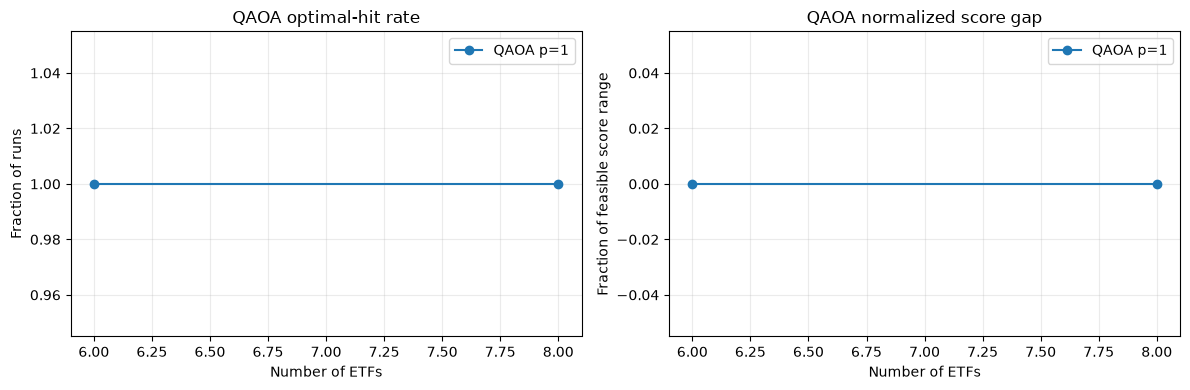

In [11]:
summary = benchmark.groupby(["ETFs", "method", "depth"], as_index=False).agg(
    hit_rate=("hit", "mean"), avg_gap=("gap", "mean"),
    valid_rate=("feasible_rate", "mean"), avg_seconds=("seconds", "mean"))
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for p, data in summary[summary.method == "QAOA"].groupby("depth"):
    axes[0].plot(data.ETFs, data.hit_rate, marker="o", label=f"QAOA p={p}")
    axes[1].plot(data.ETFs, data.avg_gap, marker="o", label=f"QAOA p={p}")
axes[0].set(title="QAOA optimal-hit rate", xlabel="Number of ETFs", ylabel="Fraction of runs")
axes[1].set(title="QAOA normalized score gap", xlabel="Number of ETFs", ylabel="Fraction of feasible score range")
for a in axes: a.legend(); a.grid(alpha=.25)
plt.tight_layout()
plt.savefig("qaoa_scaling.png", dpi=160)
plt.show()

## 10. Walk-forward investment backtest

This secondary evaluation uses the **same predictions, risk estimates, and costs** for every optimizer. Each month's next-month realized ETF return is withheld until after the selection.

For a manageable run, classical and greedy are evaluated for `BACKTEST_MONTHS`, while QAOA is evaluated for the **last `QAOA_MONTHS`**. The final financial comparison is made **only on months common to all strategies**, never against a full-history classical curve.

Trading cost = `TRADING_COST_BPS / 10000 × sum(abs(new_weight - old_weight))`. Initial allocation is costed from cash. Returns are approximated using fixed weights within a month; small deviations from exact month-end buy-and-hold mechanics are possible.

In [12]:
# Use six ETFs for the full backtest initially; optimization scaling is tested above.
BACKTEST_ETFS = ALL_ETFS[:6]
qaoa_dates = set(test_dates[-QAOA_MONTHS:])
backtest_rows = []
last_weights = {"Exhaustive": np.zeros(len(BACKTEST_ETFS)),
                "Greedy": np.zeros(len(BACKTEST_ETFS)),
                "QAOA": np.zeros(len(BACKTEST_ETFS))}
for date in test_dates:
    # Start every strategy from cash at the first matched quantum test month.
    # This makes trading costs comparable over the matched test period.
    if date == min(qaoa_dates):
        for key in last_weights:
            last_weights[key] = np.zeros(len(BACKTEST_ETFS))
    mu_d, cov_d = forecast_at(date, BACKTEST_ETFS)
    exact_bits, exact_score, worst_score, _ = exhaustive(mu_d, cov_d)
    greedy_bits, g_score, _ = greedy(mu_d, cov_d)
    decisions = [("Exhaustive", exact_bits, exact_score), ("Greedy", greedy_bits, g_score)]
    if date in qaoa_dates:
        qb, qs, _, _, _ = run_qaoa(mu_d, cov_d, depth=DEPTHS[0], seed=0)
        if qb is not None:
            decisions.append(("QAOA", qb, qs))
    realized = monthly.loc[date + pd.offsets.MonthEnd(1), BACKTEST_ETFS].values.astype(float)
    for method, bits, value in decisions:
        weight = bits / CHOOSE
        turnover = float(np.abs(weight - last_weights[method]).sum())
        net = float(weight @ realized - turnover * TRADING_COST_BPS / 10000)
        backtest_rows.append({"decision_month": date, "realized_month": date + pd.offsets.MonthEnd(1),
                              "method": method, "net_return": net,
                              "turnover": turnover, "score": value,
                              "selected": ", ".join(np.array(BACKTEST_ETFS)[bits==1])})
        last_weights[method] = weight

backtest = pd.DataFrame(backtest_rows)
backtest.to_csv("portfolio_backtest.csv", index=False)
matched_dates = set(backtest[backtest.method == "QAOA"].realized_month)
matched = backtest[backtest.realized_month.isin(matched_dates)].copy()
print("Matched test months:", len(matched_dates))
display(matched.tail(12))

Matched test months: 1


,decision_month,realized_month,method,net_return,turnover,score,selected
70,2025-11-30,2025-12-31,Exhaustive,0.040839,1.0,0.309578,"XLE, XLI, XLP"
71,2025-11-30,2025-12-31,Greedy,0.040839,1.0,0.309578,"XLE, XLI, XLP"
72,2025-11-30,2025-12-31,QAOA,0.040839,1.0,0.309578,"XLE, XLI, XLP"


Matched-period performance (all methods on identical months):


,method,months,total_return,annualized_sharpe
0,Exhaustive,1,0.040839,NaN
1,Greedy,1,0.040839,NaN
2,QAOA,1,0.040839,NaN


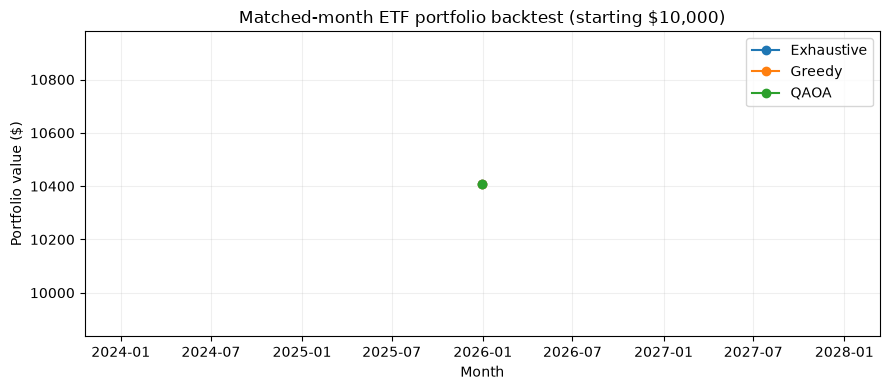

In [13]:
def performance(frame):
    result = []
    for method, group in frame.groupby("method"):
        r = group.sort_values("realized_month").net_return.to_numpy()
        std = r.std(ddof=1) if len(r) >= 2 else np.nan
        # Annualized Sharpe using a fixed 0% risk-free-rate assumption.
        sharpe = np.sqrt(12) * r.mean()/std if std and std > 0 else np.nan
        result.append({"method": method, "months": len(r),
                       "total_return": np.prod(1+r)-1,
                       "annualized_sharpe": sharpe})
    return pd.DataFrame(result)

print("Matched-period performance (all methods on identical months):")
display(performance(matched))

plt.figure(figsize=(9, 4))
for method, group in matched.groupby("method"):
    group = group.sort_values("realized_month")
    values = 10000 * (1+group.net_return).cumprod()
    plt.plot(group.realized_month, values, marker="o", label=method)
plt.title("Matched-month ETF portfolio backtest (starting $10,000)")
plt.xlabel("Month")
plt.ylabel("Portfolio value ($)")
plt.legend()
plt.grid(alpha=.2)
plt.tight_layout()
plt.savefig("matched_portfolio_growth.png", dpi=160)
plt.show()

## 11. Statistical test for Sharpe ratios (secondary)

For **24 or more matched months**, estimate a 95% confidence interval for the difference between QAOA's and Exhaustive's *annualized Sharpe ratios* using a **paired circular moving-block bootstrap** (3-month blocks, 1,000 resamples). For very short samples, we report that evidence is insufficient and do not make a significance claim.

A *meaningful practical improvement* is set **in advance** to at least `+0.10` annualized Sharpe. This is a project threshold rather than an industry standard. The test is exploratory: bootstrap confidence intervals can be unstable with short or nonstationary financial series.

In [14]:
def sharpe(x):
    sd = x.std(ddof=1)
    return float(np.sqrt(12)*x.mean()/sd) if sd > 0 else np.nan

def sharpe_bootstrap(frame, a="QAOA", b="Exhaustive", reps=1000, block=3):
    pivot = frame.pivot_table(index="realized_month", columns="method", values="net_return").dropna(subset=[a,b])
    if len(pivot) < 24:
        print(f"Only {len(pivot)} matched months. Need at least 24 for this exploratory bootstrap; skipping.")
        return None
    values = pivot[[a,b]].to_numpy()
    n = len(values)
    observed = sharpe(values[:,0]) - sharpe(values[:,1])
    rng = np.random.default_rng(SEED)
    samples = []
    for _ in range(reps):
        starts = rng.integers(0, n, size=int(np.ceil(n/block)))
        idx = np.concatenate([(np.arange(s, s+block) % n) for s in starts])[:n]
        chunk = values[idx]
        samples.append(sharpe(chunk[:,0]) - sharpe(chunk[:,1]))
    ci = np.nanpercentile(samples, [2.5,97.5])
    print("Sharpe difference", a, "minus", b, ":", round(observed, 3))
    print("Paired block bootstrap 95% CI:", np.round(ci, 3))
    print("CI excludes zero:", bool(ci[0] > 0 or ci[1] < 0))
    print("Practical-improvement threshold: +0.10 annualized Sharpe")
    return observed, ci

bootstrap_result = sharpe_bootstrap(matched)

Only 1 matched months. Need at least 24 for this exploratory bootstrap; skipping.


## 12. What to put in your report

**Main finding:** Does QAOA reach the known exhaustive optimum? Does its hit rate decrease as the ETF count grows? Does deeper QAOA improve results, and at what computational cost? Compare it to greedy as well.

**Secondary finding:** On *matched* historical test months, did the resulting portfolios deliver different net returns and Sharpe ratios? Use the paired block-bootstrap method only when enough observations exist. Avoid claims of statistical significance with six or twelve months.

**Important caveats:**

- Exhaustive search always maximizes the **same specified objective**; QAOA cannot exceed it on that objective.
- QAOA may sometimes outperform in *realized future-month returns* due to estimation noise; this is not proof of superior optimization.
- A standard QAOA simulation is not evidence of quantum speedup. Classical alternatives include greedy and more advanced optimization techniques.
- The six-to-twelve ETF results are a small proof of concept, not broad portfolio-management advice.
- Forecasts are annualized month-ahead predictions; covariance estimates and return-risk preference are assumptions.
- We use a constant 0% risk-free rate for the demonstration Sharpe ratio; a final report could substitute historical Treasury yields, consistently timed.
- QAOA parameters are optimized using ideal statevector expected energies and shots only at final measurement. Hardware or shot-based optimization could give different results.
- State the exact method settings, training/test dates, number of seeds, shots, p, penalty, and risk parameter in your report.

**QAOA application references to review:**

- Brandhofer et al. (2023), *Benchmarking the performance of portfolio optimization with QAOA*, Quantum Information Processing.
- Research on cardinality-constrained QAOA, mixer selection and parameter tuning for portfolio optimization.
- Bailey et al., *The Probability of Backtest Overfitting* (2017).

**Software reference:** https://qiskit.qotlabs.org/docs/api/qiskit/qiskit.circuit.library.qaoa_ansatz

**Data credit:** https://github.com/manisahni/marketdata

### Saved result files

`qaoa_benchmark.csv`, `qaoa_scaling.png`, `portfolio_backtest.csv`, `matched_portfolio_growth.png`. Use Colab's file browser to download them.